# ML Assignment 2 - Online Shoppers Purchase Prediction

M.Tech AIML, Machine Learning, Assignment 2

| | |
|---|---|
| **Name** | Parth Kaushik |
| **BITS ID** | 2026AJ05016 |

Dataset used: Online Shoppers Purchasing Intention dataset from UCI (id 468). Each row is one
browsing session and the target column `Revenue` tells whether the user ended up buying something.

Steps followed in this notebook:
1. Load the data and do some basic EDA
2. Remove duplicate rows and split into 80% train / 20% test (test part is saved as `test_data.csv`)
3. Train and tune Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes and SVM
4. Evaluate all five on the test set (Accuracy, AUC, Precision, Recall, F1, MCC)
5. Save the trained pipelines in the `model/` folder so the Streamlit app can load them

In [1]:
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             matthews_corrcoef, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# notebook can be opened from project folder or from inside model/
base_dir = Path.cwd() if (Path.cwd() / "app.py").exists() else Path.cwd().parent
data_path = base_dir / "data" / "online_shoppers_intention.csv"
model_dir = base_dir / "model"
test_csv_path = base_dir / "test_data.csv"

TARGET = "Revenue"
SEED = 2611
TEST_SIZE = 0.2

print("Working folder:", base_dir.name)

Working folder: ml-assignment-2


## 1. Loading the data and EDA

In [2]:
shoppers = pd.read_csv(data_path)
print("Shape:", shoppers.shape)
print("Missing values:", shoppers.isna().sum().sum())
print("Duplicate rows:", shoppers.duplicated().sum())
shoppers.head()

Shape: (12330, 18)
Missing values: 0
Duplicate rows: 125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
shoppers.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


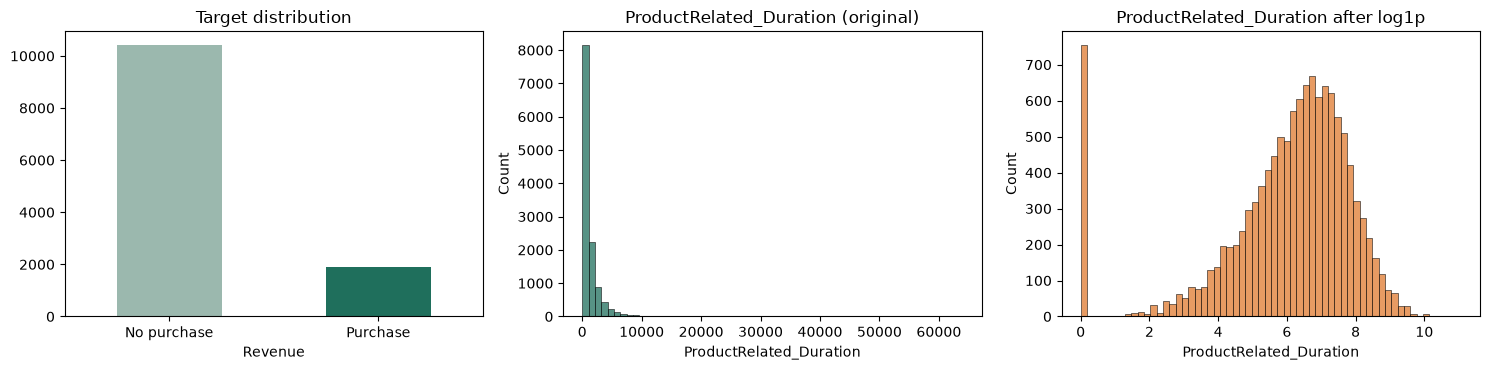

Revenue
False    0.8453
True     0.1547
Name: proportion, dtype: float64


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

shoppers[TARGET].value_counts().rename({False: "No purchase", True: "Purchase"}).plot.bar(
    ax=ax[0], color=["#9BB8AE", "#1F6F5C"], rot=0)
ax[0].set_title("Target distribution")

sns.histplot(shoppers["ProductRelated_Duration"], bins=60, ax=ax[1], color="#1F6F5C")
ax[1].set_title("ProductRelated_Duration (original)")

sns.histplot(np.log1p(shoppers["ProductRelated_Duration"]), bins=60, ax=ax[2], color="#E07A2F")
ax[2].set_title("ProductRelated_Duration after log1p")
plt.tight_layout()
plt.show()

print(shoppers[TARGET].value_counts(normalize=True).round(4))

In [5]:
# checking how buyers and non-buyers differ on a few columns
print(shoppers.groupby(TARGET)[["PageValues", "ExitRates", "BounceRates", "ProductRelated"]].mean().round(3))

         PageValues  ExitRates  BounceRates  ProductRelated
Revenue                                                    
False         1.976      0.047        0.025          28.715
True         27.265      0.020        0.005          48.210


**Observations from EDA**

- There are no missing values. 125 rows are exact duplicates, I am dropping them before the split
  so that the same row does not end up in both train and test.
- Only about 15.5% sessions have Revenue = True, so the data is imbalanced. Because of this I used
  F1 for tuning and I am mainly comparing models on AUC, F1 and MCC instead of only accuracy.
- Page counts, durations and PageValues are heavily right skewed, so log1p is applied before scaling.
- OperatingSystems, Browser, Region and TrafficType are stored as numbers but they are actually
  category codes, so I one-hot encoded them.

## 2. Feature lists, removing duplicates and train-test split

In [6]:
log_cols = ["Administrative", "Administrative_Duration", "Informational",
            "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
            "PageValues"]
rate_cols = ["BounceRates", "ExitRates", "SpecialDay"]
cat_cols = ["Month", "VisitorType", "Weekend", "OperatingSystems", "Browser",
            "Region", "TrafficType"]
features = log_cols + rate_cols + cat_cols
print("Number of input features:", len(features))

df = shoppers.drop_duplicates().reset_index(drop=True)
print("Rows before:", len(shoppers), " after removing duplicates:", len(df))

X = df[features]
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
print("Train rows:", len(X_train), " Test rows:", len(X_test))
print(f"Purchase ratio -> train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")

# saving the test split as it is, this is the file to upload in the app
test_data = X_test.copy()
test_data[TARGET] = y_test.astype(bool)
test_data.to_csv(test_csv_path, index=False)
print("test_data.csv saved with shape", test_data.shape)

Number of input features: 17
Rows before: 12330  after removing duplicates: 12205
Train rows: 9764  Test rows: 2441
Purchase ratio -> train: 0.156, test: 0.156
test_data.csv saved with shape (2441, 18)


## 3. Preprocessing

In [7]:
def make_preprocessor():
    """Builds the preprocessing step: log + scaling for numeric columns, one-hot for categorical."""
    log_then_scale = Pipeline([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    # sparse_output=False because GaussianNB does not accept sparse matrix
    # handle_unknown="ignore" so a new category in uploaded file does not crash the app
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([
        ("log_num", log_then_scale, log_cols),
        ("rate_num", StandardScaler(), rate_cols),
        ("cat", one_hot, cat_cols),
    ])

## 4. Models and parameter grids

In [8]:
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib",
}

models_to_try = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, random_state=SEED),
        {"clf__C": [0.01, 0.1, 1.0, 10.0],
         "clf__class_weight": [None, "balanced"]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"clf__criterion": ["gini", "entropy"],
         "clf__max_depth": [4, 6, 8, 12, None],
         "clf__min_samples_leaf": [1, 10, 30],
         "clf__class_weight": [None, "balanced"]},
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 11, 21, 35],
         "clf__weights": ["uniform", "distance"],
         "clf__p": [1, 2]},
    ),
    "Naive Bayes": (
        GaussianNB(),
        {"clf__var_smoothing": np.logspace(-9, -1, 9)},
    ),
    # grid search runs without probability=True (much faster),
    # best SVM is refitted later with probability=True for AUC
    "Support Vector Machine": (
        SVC(kernel="rbf", random_state=SEED),
        {"clf__C": [0.5, 1.0, 5.0],
         "clf__gamma": ["scale", 0.01],
         "clf__class_weight": [None, "balanced"]},
    ),
}


def get_metrics(model, X, y):
    """Predicts on X and returns the 6 metrics asked in the assignment."""
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    return {
        "Accuracy": accuracy_score(y, pred),
        "AUC": roc_auc_score(y, prob),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "MCC": matthews_corrcoef(y, pred),
    }

## 5. Training with 5-fold GridSearchCV (scoring = F1) and saving the models

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results, best_params, trained = [], {}, {}

for name, (clf, param_grid) in models_to_try.items():
    t0 = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    gs = GridSearchCV(pipe, param_grid, scoring="f1", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    best_model = gs.best_estimator_

    if name == "Support Vector Machine":
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", FutureWarning)
            best_model.set_params(clf__probability=True)
            best_model.fit(X_train, y_train)

    scores = get_metrics(best_model, X_test, y_test)
    results.append({"ML Model Name": name, **scores})
    best_params[name] = {k.replace("clf__", ""): (float(v) if isinstance(v, np.floating) else v)
                         for k, v in gs.best_params_.items()}
    trained[name] = best_model
    joblib.dump(best_model, model_dir / model_files[name])

    print(f"{name}: CV F1 = {gs.best_score_:.4f}, time = {time.time() - t0:.1f}s, best = {best_params[name]}")

Logistic Regression: CV F1 = 0.6587, time = 2.8s, best = {'C': 0.01, 'class_weight': 'balanced'}


Decision Tree: CV F1 = 0.6429, time = 3.2s, best = {'class_weight': None, 'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 30}


KNN: CV F1 = 0.6219, time = 5.2s, best = {'n_neighbors': 21, 'p': 2, 'weights': 'distance'}


Naive Bayes: CV F1 = 0.5213, time = 0.3s, best = {'var_smoothing': 0.1}


Support Vector Machine: CV F1 = 0.6650, time = 20.4s, best = {'C': 0.5, 'class_weight': 'balanced', 'gamma': 0.01}


## 6. Comparison of all models on test data

In [10]:
metrics_df = pd.DataFrame(results).round(4)
metrics_df.to_csv(model_dir / "metrics_summary.csv", index=False)

# details needed by app.py
meta = {
    "dataset": "UCI Online Shoppers Purchasing Intention (id 468)",
    "target": TARGET,
    "class_labels": {"0": "No purchase", "1": "Purchase"},
    "feature_columns": features,
    "log_columns": log_cols,
    "rate_columns": rate_cols,
    "categorical": cat_cols,
    "model_files": model_files,
    "best_params": best_params,
    "seed": SEED,
    "rows_after_dedup": len(df),
    "train_rows": len(X_train),
    "test_rows": len(X_test),
}
with open(model_dir / "model_metadata.json", "w") as f:
    json.dump(meta, f, indent=2)

metrics_df.set_index("ML Model Name")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8828,0.9261,0.5930,0.8010,0.6815,0.6221
Decision Tree,0.9058,0.9196,0.7452,0.6047,0.6676,0.6180
KNN,0.8914,0.9189,0.6997,0.5366,0.6074,0.5521
Naive Bayes,0.7538,0.8846,0.3768,0.8770,0.5271,0.4590
Support Vector Machine,0.8849,0.9273,0.5973,0.8115,0.6881,0.6305


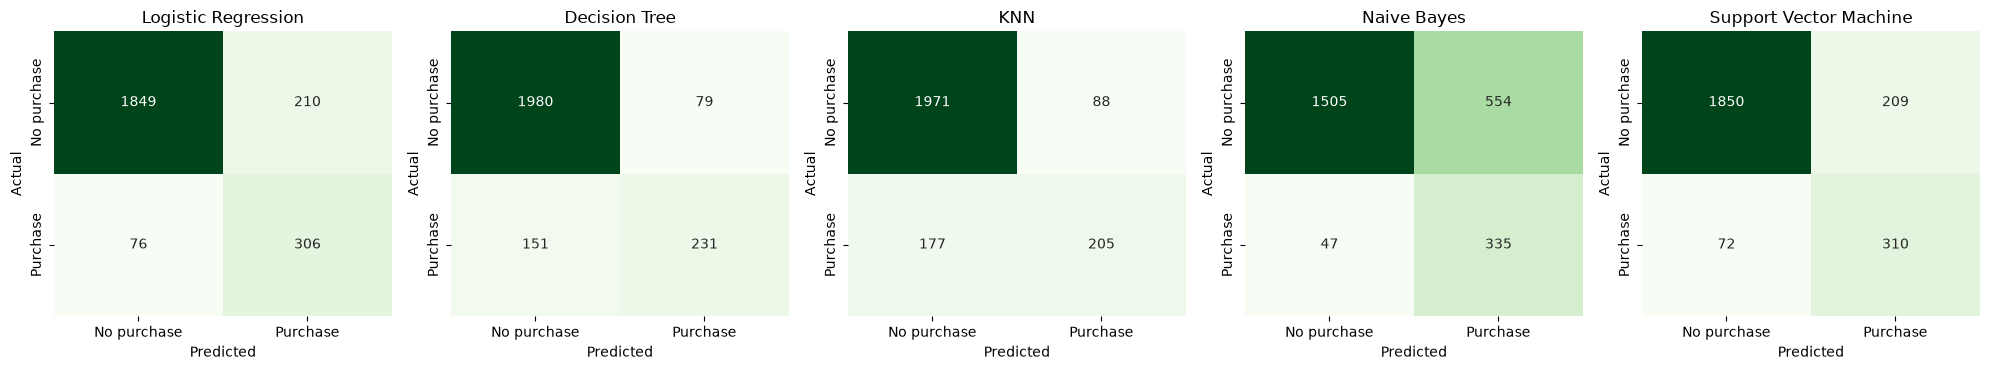

In [11]:
fig, ax = plt.subplots(1, 5, figsize=(20, 3.8))
labels = ["No purchase", "Purchase"]
for i, (name, model) in enumerate(trained.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax[i])
    ax[i].set_title(name)
    ax[i].set_xlabel("Predicted")
    ax[i].set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 7. Which features matter the most?

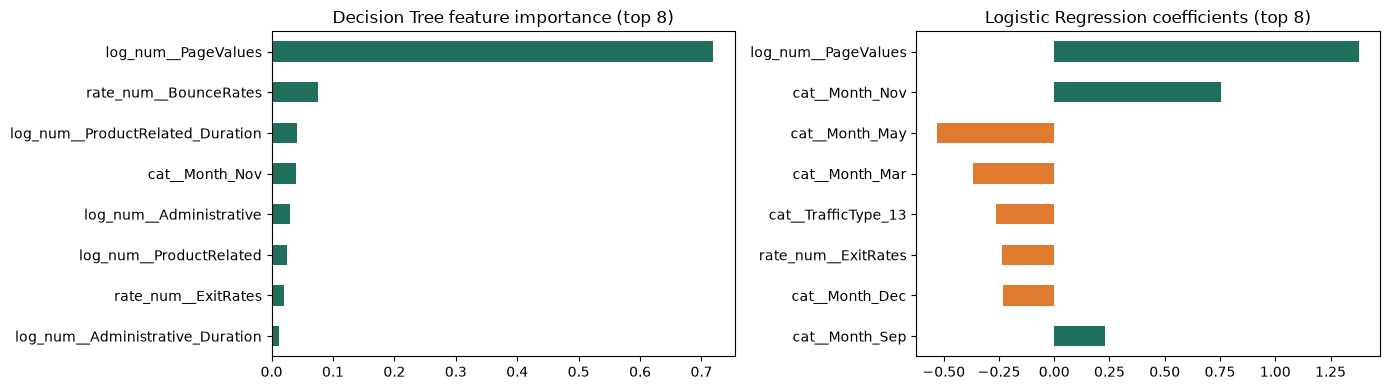

In [12]:
feat_names = trained["Decision Tree"].named_steps["prep"].get_feature_names_out()

tree_imp = pd.Series(trained["Decision Tree"].named_steps["clf"].feature_importances_,
                     index=feat_names).sort_values(ascending=False).head(8)
lr_coef = pd.Series(trained["Logistic Regression"].named_steps["clf"].coef_[0],
                    index=feat_names).sort_values(key=abs, ascending=False).head(8)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
tree_imp[::-1].plot.barh(ax=ax[0], color="#1F6F5C")
ax[0].set_title("Decision Tree feature importance (top 8)")
lr_coef[::-1].plot.barh(ax=ax[1], color=np.where(lr_coef[::-1] > 0, "#1F6F5C", "#E07A2F"))
ax[1].set_title("Logistic Regression coefficients (top 8)")
plt.tight_layout()
plt.show()

## 8. Conclusion

- SVM (RBF kernel) got the best AUC, F1 and MCC on the test set, so I am taking it as the overall best model.
- Logistic Regression is very close to SVM and is much simpler and faster.
- Decision Tree has the best accuracy and precision. Naive Bayes has the best recall but gives a lot of false positives.
- PageValues is the most important feature in every model.

Model wise observations are written in the README. The saved models in `model/` are used directly
by `app.py`.